In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression

cancer = load_breast_cancer()


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

scaler = StandardScaler()
data_scaled = scaler.fit_transform(cancer.data)

X_train, X_test, y_train, y_test = train_test_split(data_scaled, cancer.target, test_size= 0.3, random_state= 42)


In [3]:
from sklearn.metrics import accuracy_score, roc_auc_score

lr_clf = LogisticRegression() # solver = 'lbfgs'가 기본값
lr_clf.fit(X_train, y_train)
lr_pred = lr_clf.predict(X_test)
lr_pred_proba = lr_clf.predict_proba(X_test)[:,1]

print(accuracy_score(y_test, lr_pred), roc_auc_score(y_test, lr_pred_proba))

0.9824561403508771 0.9980893592004703


In [4]:
solvers = ['lbfgs', 'liblinear', 'newton-cg', 'sag', 'saga'] # solve 파라미터 종류

for solver in solvers:
    lr_clf = LogisticRegression(solver = solver, max_iter= 600)
    lr_clf.fit(X_train, y_train)
    lr_pred = lr_clf.predict(X_test)
    lr_pred_proba = lr_clf.predict_proba(X_test)[:,1]
    print(solver, accuracy_score(y_test, lr_pred),
          roc_auc_score(y_test, lr_pred_proba))


lbfgs 0.9824561403508771 0.9980893592004703
liblinear 0.9824561403508771 0.9980893592004703
newton-cg 0.9824561403508771 0.9980893592004703
sag 0.9824561403508771 0.9980893592004703
saga 0.9824561403508771 0.9980893592004703


In [5]:
from sklearn.model_selection import GridSearchCV

params = {'solver': ['liblinear', 'lbfgs'],
          'l1_ratio' : [0, 1],
          'C' : [0.01, 0.1, 1, 5, 10]}
lr_clf = LogisticRegression()
grid_clf = GridSearchCV(lr_clf, param_grid= params, scoring= 'accuracy', cv= 3)

grid_clf.fit(data_scaled, cancer.target)
print(grid_clf.best_params_, grid_clf.best_score_)

c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\sklearn\linear_model\_logistic.py:1476: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\sklearn\linear_model\_logistic.py:1476: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\sklearn\linear_model\_logistic.py:1476: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\sklearn\linear_model\_logistic.py:1476: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\sklearn\linear_model\_logistic.py:1476: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.w

{'C': 0.1, 'l1_ratio': 0, 'solver': 'liblinear'} 0.9789102385593614


c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\sklearn\linear_model\_logistic.py:1476: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


In [6]:
# 회귀 트리

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [7]:
housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns= housing.feature_names)

df['PRICE'] = housing.target
y_target = df['PRICE']
X_data = df.drop(['PRICE'], axis = 1, inplace= False)

rf = RandomForestRegressor(random_state= 0, n_estimators= 1000,
                           n_jobs= -1)

neg_mse_scores = cross_val_score(rf, X_data, y_target,
                                 scoring= 'neg_mean_squared_error', cv = 5)
rmse_score = np.sqrt(-1 * neg_mse_scores)
avg_rmse = np.mean(rmse_score)

print(np.round(neg_mse_scores, 2))
print(np.round(rmse_score, 2))
print(np.round(avg_rmse, 3))

[-0.52 -0.34 -0.37 -0.44 -0.46]
[0.72 0.59 0.61 0.66 0.68]
0.651


In [8]:
def get_model_cv_prediction(model, X_data, y_target):
    neg_mse_scores = cross_val_score(model, X_data, y_target,
                                 scoring= 'neg_mean_squared_error', cv = 5)
    rmse_score = np.sqrt(-1 * neg_mse_scores)
    avg_rmse = np.mean(rmse_score)
    print('######', model.__class__.__name__,'######')
    print(np.round(neg_mse_scores, 2))
    print(np.round(rmse_score, 2))
    print(np.round(avg_rmse, 3))

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

dt = DecisionTreeClassifier(random_state= 42, max_depth= 4)
rf = RandomForestRegressor(random_state= 42, n_estimators= 1000, n_jobs=-1)
gb = GradientBoostingClassifier(random_state= 42, n_estimators=1000)
xgb = XGBRegressor(n_estimators= 1000)
lgb = LGBMRegressor(n_estimators= 1000)

models = [dt, rf, gb, xgb, lgb]

for model in models:
    get_model_cv_prediction(model, X_data, y_target)

###### DecisionTreeClassifier ######
[nan nan nan nan nan]
[nan nan nan nan nan]
nan
###### RandomForestRegressor ######
[-0.52 -0.34 -0.37 -0.44 -0.46]
[0.72 0.59 0.61 0.66 0.68]
0.651
###### GradientBoostingClassifier ######
[nan nan nan nan nan]
[nan nan nan nan nan]
nan
###### XGBRegressor ######
[-0.43 -0.37 -0.45 -0.49 -0.53]
[0.65 0.61 0.67 0.7  0.73]
0.673
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000429 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1838
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 8
[LightGBM] [Info] Start training from score 2.164930
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000317 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1838
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 8
[Lig

<Axes: >

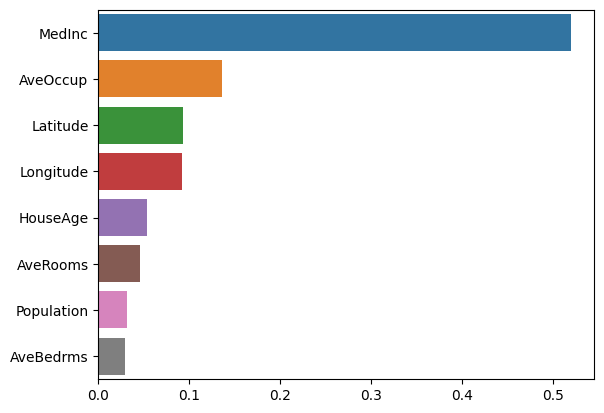

In [10]:
import seaborn as sns


rf = RandomForestRegressor(n_estimators= 1000, n_jobs= -1)
rf.fit(X_data, y_target)
feature_series = pd.Series(data = rf.feature_importances_, index= X_data.columns)
feature_series = feature_series.sort_values(ascending= False)
sns.barplot(x= feature_series, y= feature_series.index)

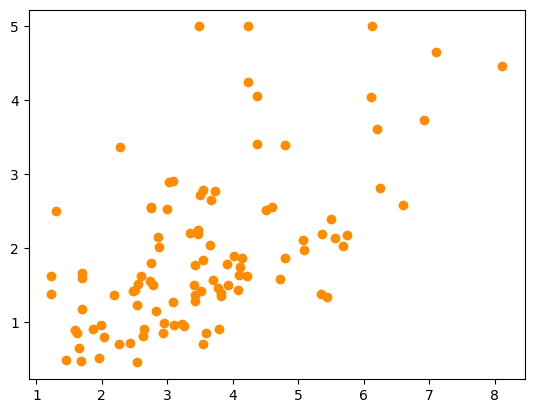

In [11]:
import matplotlib.pyplot as plt

df_sample = df[['MedInc', 'PRICE']]
df_sample = df_sample.sample(n = 100, random_state= 42)
plt.figure()
plt.scatter(df_sample.MedInc, df_sample.PRICE, c = 'darkorange')

In [17]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor


lr = LinearRegression()
dt1 = DecisionTreeRegressor(max_depth= 2)
dt2 = DecisionTreeRegressor(max_depth= 2)

X_test = np.arange(1.0, 10.0, 0.09).reshape(-1, 1)
X_feature = df_sample['MedInc'].values.reshape(-1, 1)
y_target = df_sample['PRICE'].values.reshape(-1, 1)

lr.fit(X_feature, y_target)
dt1.fit(X_feature, y_target)
dt2.fit(X_feature, y_target)

pred_lr = lr.predict(X_test)
pred_dt1 = lr.predict(X_test)
pred_dt2 = lr.predict(X_test)

Text(0.5, 1.0, 'Decision Tree - Max Depth =2')

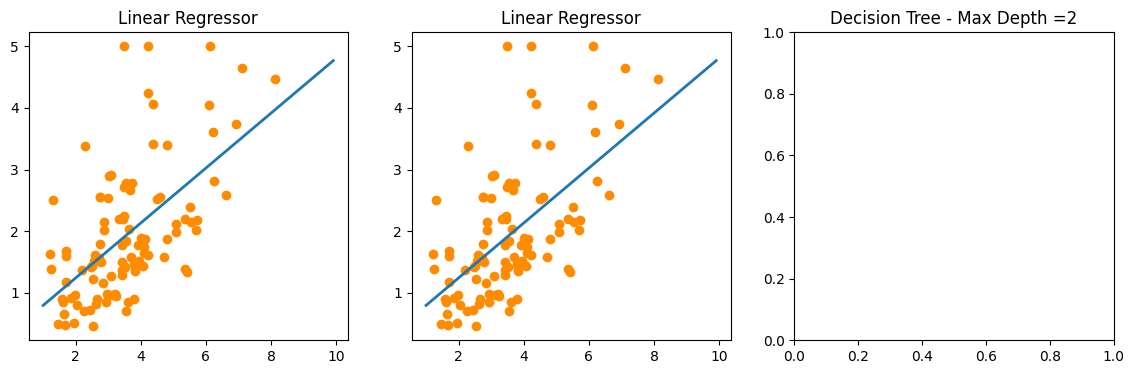

In [18]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize = (14, 4), ncols= 3)

ax1.set_title('Linear Regressor')
ax1.scatter(df_sample.MedInc, df_sample.PRICE, c = 'darkorange')
ax1.plot(X_test, pred_lr, label = 'linear', linewidth= 2)

ax2.set_title('Linear Regressor')
ax2.scatter(df_sample.MedInc, df_sample.PRICE, c = 'darkorange')
ax2.plot(X_test, pred_lr, label = 'linear', linewidth= 2)

ax3.set_title('Decision Tree - Max Depth =2')